# Projet — différences entre la NAV et le prix de marché des ETF

## Problématique

Deux actifs peuvent représenter le même investissement — l'ETF et le portefeuille sous-jacent constitué par le fond, représenté par sa valeur nette des actifs (NAV) — tout en affichant des prix différents. L'objectif est de mesurer ces écarts, de voir s'ils sont liés au régime de marché (volatilité et liquidité) et d'observer s'ils se corrigent rapidement.

L'étude se concentre sur 4 ETF : `SPY`, `SPEM`, `SPIB` et `SPHY` répliquant respectivement le S&P 500, les marchés actions émergents, un panier d'obligations Investment Grade (à faible risque de défaut), et un panier d'obligations High Yield (à forte probabilité de défaut).
On comparera la NAV quotidienne aux prix de ces 4 ETF.

Les étapes sont : (1) nettoyer les données de NAV et de prix de clôture, (2) calculer la prime/décote, (3) comparer les écarts selon la volatilité et la liquidité, puis (4) mesurer la correction le jour suivant.

> **Architecture modulaire** : les fonctions de collecte/nettoyage, de traitement/analyse et de visualisation sont regroupées dans le dossier `src/` (`data_loader.py`, `analysis.py`, `visualization.py`).

In [1]:
from IPython.display import display

from src.data_loader import (
    fetch_and_clean_nav,
    fetch_and_clean_prices,
    fetch_and_clean_vix,
)
from src.analysis import (
    add_market_regimes,
    analyze_market_regimes,
    compute_next_day_correction,
    compute_spread_statistics,
    merge_nav_and_prices,
)
from src.visualization import (
    plot_daily_spreads,
    plot_next_day_correction,
    plot_regime_comparisons,
)

ETFS = ["SPY", "SPEM", "SPIB", "SPHY"]
START_DATE = "2012-06-19"
END_DATE = "2026-10-15"  # Borne exclusive yfinance -> jusqu'au 2026-10-14

## 1. Importation et nettoyage des données de NAV

Cette étape télécharge les historiques de NAV dans un dataframe, et les nettoie en retirant toutes les dates sans NAV. On préfère cela à de l'interpolation ou à une moyenne car on créerait alors artificiellement des écarts importants entre NAV et ETFs (les écarts étant usuellement très faibles).

La NAV (*Net Asset Value*) représente la valeur par part du portefeuille détenu par l'ETF et peut être résumée par la relation :

$$\mathrm{NAV}_t = \frac{\text{valeur des actifs du portefeuille à }t}{\text{nombre de parts de l'ETF à }t}$$

In [2]:
tickers = [t.lower() for t in ETFS]

nav = fetch_and_clean_nav(tickers)
for ticker in tickers:
    display(nav[ticker].head())

SPY (NAV) | dates invalides: 148 | NAV invalides supprimées: 0 | période: 2003-12-01 -> 2026-11-23 (5785 obs.)
SPEM (NAV) | dates invalides: 148 | NAV invalides supprimées: 2 | période: 2007-03-21 -> 2026-11-23 (4955 obs.)
SPIB (NAV) | dates invalides: 148 | NAV invalides supprimées: 0 | période: 2009-02-10 -> 2026-11-23 (4478 obs.)
SPHY (NAV) | dates invalides: 148 | NAV invalides supprimées: 0 | période: 2012-06-19 -> 2026-11-23 (3632 obs.)


,Date,NAV,Shares Outstanding,Total Net Assets
0,2003-12-01,107.61,-,-
1,2003-12-02,107.26,-,-
2,2003-12-03,107.10,-,-
3,2003-12-04,107.61,-,-
4,2003-12-05,106.79,-,-


,Date,NAV,Shares Outstanding,Total Net Assets
0,2007-03-21,56.296426,300000.0,16888927.84
1,2007-03-22,57.081256,300000.0,17124376.88
2,2007-03-23,57.316085,300000.0,17194825.49
3,2007-03-26,57.296408,300000.0,17188922.39
4,2007-03-27,57.138245,300000.0,17141473.43


,Date,NAV,Shares Outstanding,Total Net Assets
0,2009-02-10,30.000000,200000.0,6000000.00
1,2009-02-11,29.877218,200000.0,5975443.53
2,2009-02-12,29.893633,200000.0,5978726.63
3,2009-02-13,29.706208,200000.0,5941241.59
4,2009-02-17,29.843575,200000.0,5968715.06


,Date,NAV,Shares Outstanding,Total Net Assets
0,2012-06-19,25.070512,400000.0,10028204.90
1,2012-06-20,25.111529,400000.0,10044611.66
2,2012-06-21,25.161863,400000.0,10064745.34
3,2012-06-22,25.140285,400000.0,10056114.06
4,2012-06-25,25.165986,400000.0,10066394.29


## 2. Importation des prix de marché et des volumes

On récupère les prix de clôture et les volumes des quatre ETF via Yahoo Finance sur la fenêtre commune (`START_DATE = 2012-06-19` jusqu'au `2026-10-14`, `END_DATE = 2026-10-15` étant exclusive dans `yfinance`). Le prix de marché est celui auquel l'ETF s'échange en bourse. Les volumes nous serviront de proxy pour calculer la liquidité d'un ETF.
Comme précédemment, on nettoie le dataframe et on en retire les valeurs manquantes.

Le prix utilisé est le cours de clôture :

$$P_t^{\mathrm{marché}} = \mathrm{Close}_t$$

In [3]:
prix = fetch_and_clean_prices(ETFS, start_date=START_DATE, end_date=END_DATE)
for ticker in ETFS:
    display(prix[ticker][["Close", "Volume"]].head())

SPY (Prix) | dates invalides: 0 | Close invalides supprimés: 0 | période: 2012-06-19 -> 2026-10-14 (3601 obs.)
SPEM (Prix) | dates invalides: 0 | Close invalides supprimés: 0 | période: 2012-06-19 -> 2026-10-14 (3601 obs.)
SPIB (Prix) | dates invalides: 0 | Close invalides supprimés: 0 | période: 2012-06-19 -> 2026-10-14 (3601 obs.)
SPHY (Prix) | dates invalides: 0 | Close invalides supprimés: 0 | période: 2012-06-19 -> 2026-10-14 (3601 obs.)


Price,Close,Volume
0,135.699997,137382600
1,135.479996,206451800
2,132.440002,205272200
3,133.460007,130029200
4,131.320007,146375700


Price,Close,Volume
0,30.070000,4800
1,30.004999,54200
2,28.959999,19800
3,29.129999,23200
4,28.610001,8200


Price,Close,Volume
0,33.980000,23800
1,33.980000,34900
2,34.090000,271300
3,34.000000,113600
4,34.060001,14400


Price,Close,Volume
0,25.400000,4000
1,25.559999,2100
2,25.459999,1400
3,25.500000,800
4,25.500000,1600


## 3. Fusion des dataframes NAV et ETF et calcul des primes et décotes

La fusion ne conserve que les dates communes entre NAV et prix de clôture. Pour chaque date, l'écart relatif est calculé ainsi :

$$\mathrm{Prime/Décote}_t = \frac{P_t^{\mathrm{marché}} - \mathrm{NAV}_t}{\mathrm{NAV}_t} \times 100$$

Une valeur positive correspond à une prime et une valeur négative à une décote. On calcule aussi l'écart absolu :

$$\mathrm{Écart\ absolu}_t = \left|\mathrm{Prime/Décote}_t\right|$$

L'ajustement du split 2-pour-1 de SPEM avant le 16 octobre 2017 évite de confondre une rupture technique avec un véritable écart économique.

> Convention : une prime/décote positive signifie que le prix de marché est supérieur à la NAV ; une valeur négative correspond à une décote.

,ETF,Date,Close,NAV,Volume,Prime_decote_pct,Prime_decote_moyenne_30j
0,SPEM,2012-06-19,30.070000,29.831433,4800,0.799714,NaN
1,SPEM,2012-06-20,30.004999,29.905950,54200,0.331201,NaN
2,SPEM,2012-06-21,28.959999,29.324434,19800,-1.242770,NaN
3,SPEM,2012-06-22,29.129999,28.989788,23200,0.483655,NaN
4,SPEM,2012-06-25,28.610001,28.592290,8200,0.061942,0.086748


,ETF,Classe,Type,Nombre_observations,Prime_decote_moyenne_pct,Prime_decote_mediane_pct,Ecart_absolu_moyen_pct,Ecart_absolu_max_pct,Jours_au_dessus_0.25pct,Jours_au_dessus_0.5pct,Jours_au_dessus_1.0pct
0,SPEM,Actions,Actions émergentes,3601,0.0759,0.1046,0.4514,4.3401,63.6768,35.0736,8.0533
1,SPHY,Obligations,Obligations high yield,3601,0.1632,0.1483,0.3336,4.4806,45.4041,19.7445,6.1927
2,SPIB,Obligations,Obligations investment grade,3601,0.0913,0.0570,0.1315,6.1028,15.3291,3.8600,0.3055
3,SPY,Actions,Actions américaines,3601,0.0020,0.0036,0.0242,0.9004,0.3055,0.0555,0.0000


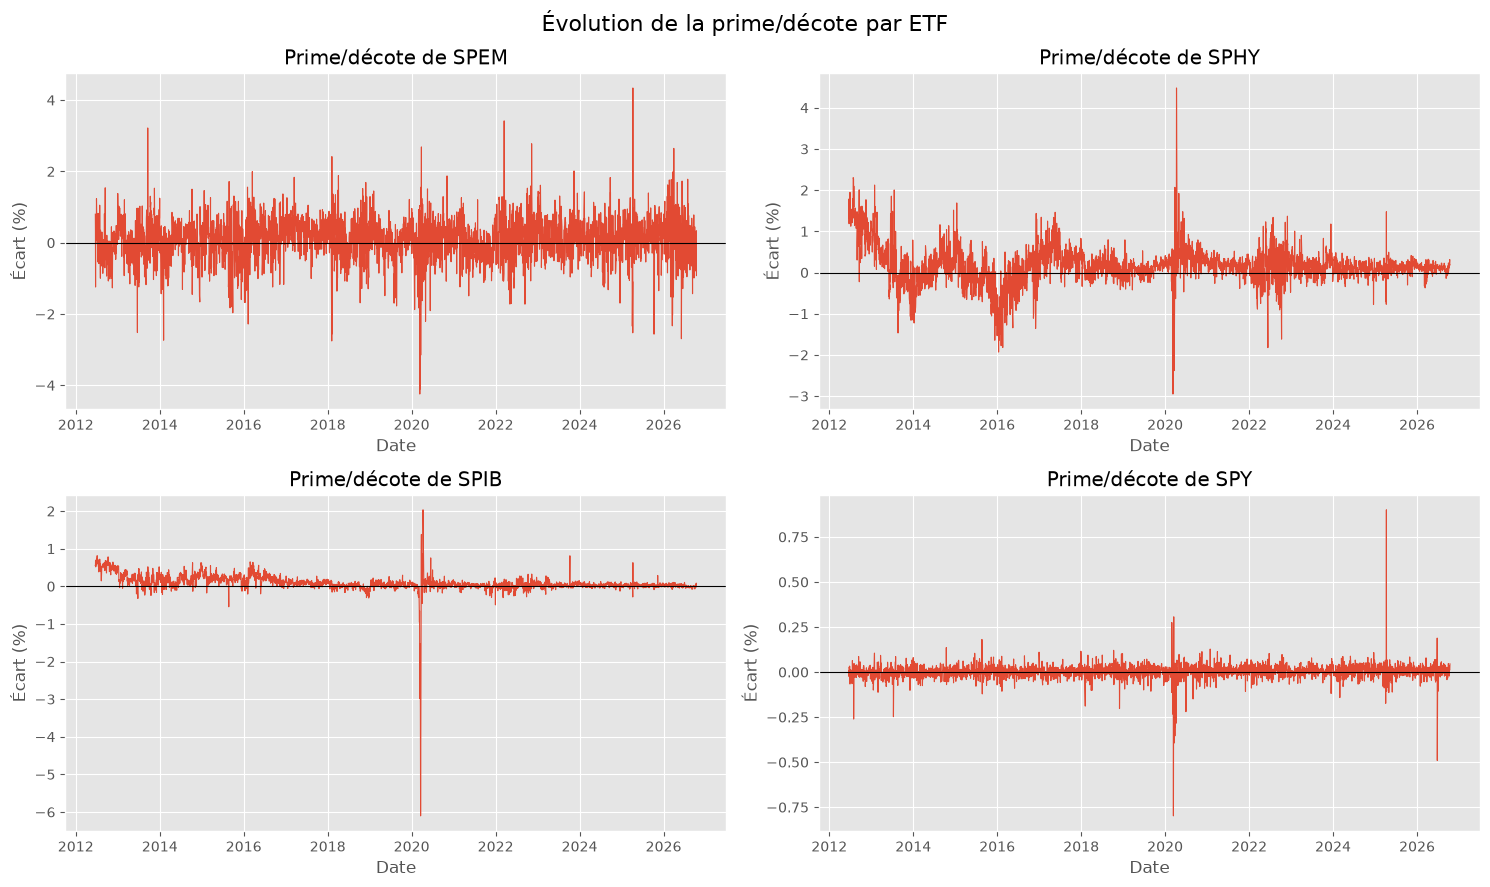

In [4]:
donnees = merge_nav_and_prices(nav, prix, ETFS)
display(donnees[["ETF", "Date", "Close", "NAV", "Volume", "Prime_decote_pct", "Prime_decote_moyenne_30j"]].head())

Statistiques_ecarts = compute_spread_statistics(donnees, thresholds=(0.25, 0.5, 1.0))
display(Statistiques_ecarts.round(4))

_ = plot_daily_spreads(donnees)

### Résultats de la fusion des données

La fusion produit **3 601 dates communes par ETF**. L'écart absolu moyen est de **0,0242 % pour SPY**, **0,1315 % pour SPIB**, **0,3336 % pour SPHY** et **0,4514 % pour SPEM**.

La proportion de jours où l'écart dépasse 0,25 % est respectivement de **0,31 %**, **15,33 %**, **45,40 %** et **63,68 %** pour SPY, SPIB, SPHY et SPEM.

SPY et SPIB suivent très étroitement leur NAV, alors que SPEM et SPHY présentent les écarts les plus fréquents entre NAV et valeur de l'ETF.

On peut attribuer cette différence au fait que les sous-jacents de SPEM et SPHY sont généralement moins liquides, ce qui rend leur achat et vente par le détenteur du fond pour recalibrer sa réplication de l'ETF plus difficile en cas de stress de marché.

Les pics observés en 2020, notamment en mars, correspondent au choc de la pandémie de Covid-19 : la forte volatilité, les ventes massives et la baisse de la liquidité ont temporairement amplifié les primes et décotes, surtout pour SPEM et SPHY.

## 4. Volatilité, liquidité et ampleur des écarts

On se demande ici si les primes et décotes importants, c'est-à-dire les écarts importants entre NAV et prix de l'ETF sont liés aux conditions de marché (volatilité et liquidité).

Le VIX sert à distinguer les régimes de volatilité faible et forte. La règle appliquée est :

$$R_{\mathrm{vol},t} = \begin{cases} \text{Faible} & \text{si } VIX_t < 15 \\ \text{Forte} & \text{si } VIX_t \geq 30 \\ \text{Intermédiaire} & \text{sinon} \end{cases}$$

Pour la liquidité, les quartiles sont calculés séparément pour chaque ETF :

$$R_{\mathrm{liq},t} = \begin{cases} \text{Faible} & \text{si } Volume_t \leq Q_{25} \\ \text{Forte} & \text{si } Volume_t \geq Q_{75} \\ \text{Intermédiaire} & \text{sinon} \end{cases}$$

L'analyse compare ensuite l'écart absolu moyen entre les régimes faible et fort, sans prétendre établir une causalité.

,Type,Regime_volatilite,Nb_jours,Prime_moyenne_pct,Ecart_absolu_moyen_pct
0,Actions américaines,Faible,1446,0.0023,0.0202
1,Actions américaines,Forte,158,-0.0186,0.0671
2,Actions émergentes,Faible,1446,0.1876,0.3752
3,Actions émergentes,Forte,158,-0.3442,0.8283
4,Obligations high yield,Faible,1446,0.1880,0.3323
5,Obligations high yield,Forte,158,0.0759,0.5096
6,Obligations investment grade,Faible,1446,0.1214,0.1314
7,Obligations investment grade,Forte,158,-0.1393,0.3412


,Type,Regime_liquidite,Nb_jours,Prime_moyenne_pct,Ecart_absolu_moyen_pct
0,Actions américaines,Faible,901,0.0067,0.0199
1,Actions américaines,Forte,901,-0.0029,0.0332
2,Actions émergentes,Faible,901,0.0668,0.4164
3,Actions émergentes,Forte,901,0.0563,0.5442
4,Obligations high yield,Faible,903,0.1574,0.4625
5,Obligations high yield,Forte,901,0.1088,0.1722
6,Obligations investment grade,Faible,901,0.2398,0.2503
7,Obligations investment grade,Forte,901,0.0304,0.0618


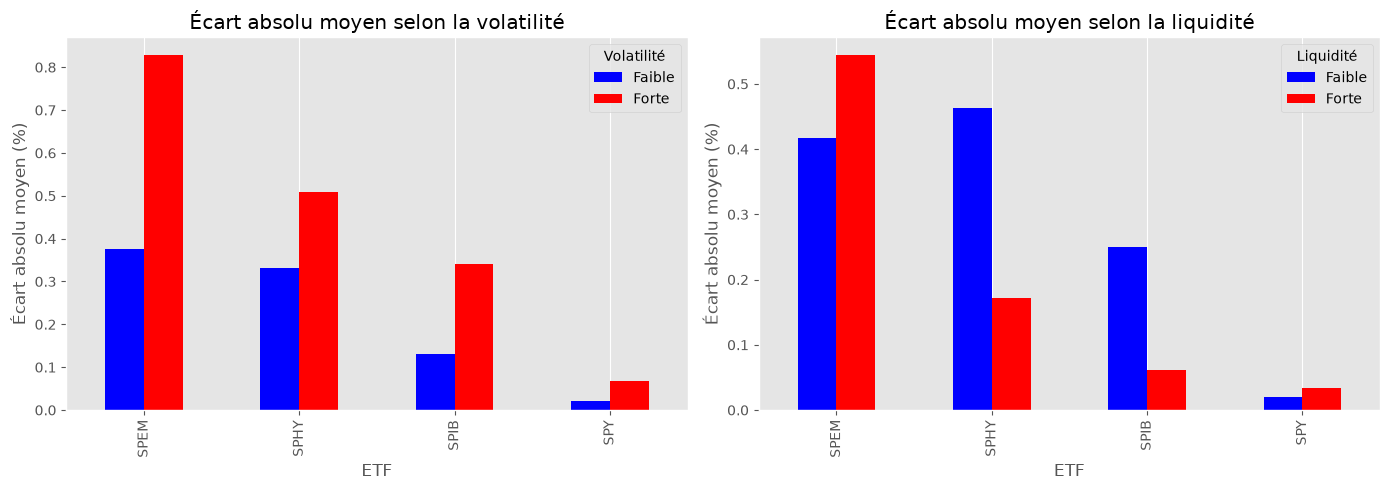

In [5]:
vix = fetch_and_clean_vix(donnees["Date"].min(), donnees["Date"].max())
donnees = add_market_regimes(donnees, vix)

comparaison_volatilite, comparaison_liquidite = analyze_market_regimes(donnees)
display(comparaison_volatilite.round(4))
display(comparaison_liquidite.round(4))

_ = plot_regime_comparisons(donnees)

### Résultats de l'analyse des conditions de marché

En forte volatilité, l'écart absolu moyen augmente pour les quatre catégories : **0,0202 % → 0,0671 %** pour les actions américaines, **0,3752 % → 0,8283 %** pour les actions émergentes, **0,1314 % → 0,3412 %** pour l'investment grade et **0,3323 % → 0,5096 %** pour le high yield. L'effet est particulièrement marqué pour SPEM.

L'effet du volume est hétérogène : l'écart augmente lorsque le volume est fort pour les actions américaines et émergentes, mais diminue pour les obligations (**0,4625 % → 0,1722 %** pour le high yield ; **0,2503 % → 0,0618 %** pour l'investment grade). Le volume est donc un proxy imparfait de la liquidité.

## 5. Correction le jour suivant

On se demande si les écarts se rétablissent le jour d'après, quand les opérateurs de marché arbitrent la différence entre la valeur de la NAV et des ETF.

On retient les écarts absolus d'au moins 0,25 %, puis on compare leur valeur avec celle de la séance suivante. La variation de l'écart est définie par :

$$\Delta_t = \mathrm{Écart\ absolu}_{t+1} - \mathrm{Écart\ absolu}_t$$

Une correction est comptée lorsque :

$$\mathrm{Correction}_t = \mathbb{1}(\Delta_t < 0)$$

Le taux de correction est ensuite :

$$\mathrm{Taux\ de\ correction} = \frac{\text{nombre de corrections}}{\text{nombre d'écarts importants observés}} \times 100$$

Dans le nuage de points, les observations sous la diagonale correspondent à une correction et celles au-dessus à une aggravation de l'écart enregistré le jour précédent.

,ETF,Classe,Type,Nb_dates,Taux_correction_pct,Variation_abs_moyenne_1j
0,SPEM,Actions,Actions émergentes,2292,68.6736,-0.1663
1,SPHY,Obligations,Obligations high yield,1635,67.2783,-0.1050
2,SPIB,Obligations,Obligations investment grade,552,65.2174,-0.0526
3,SPY,Actions,Actions américaines,11,100.0000,-0.3203


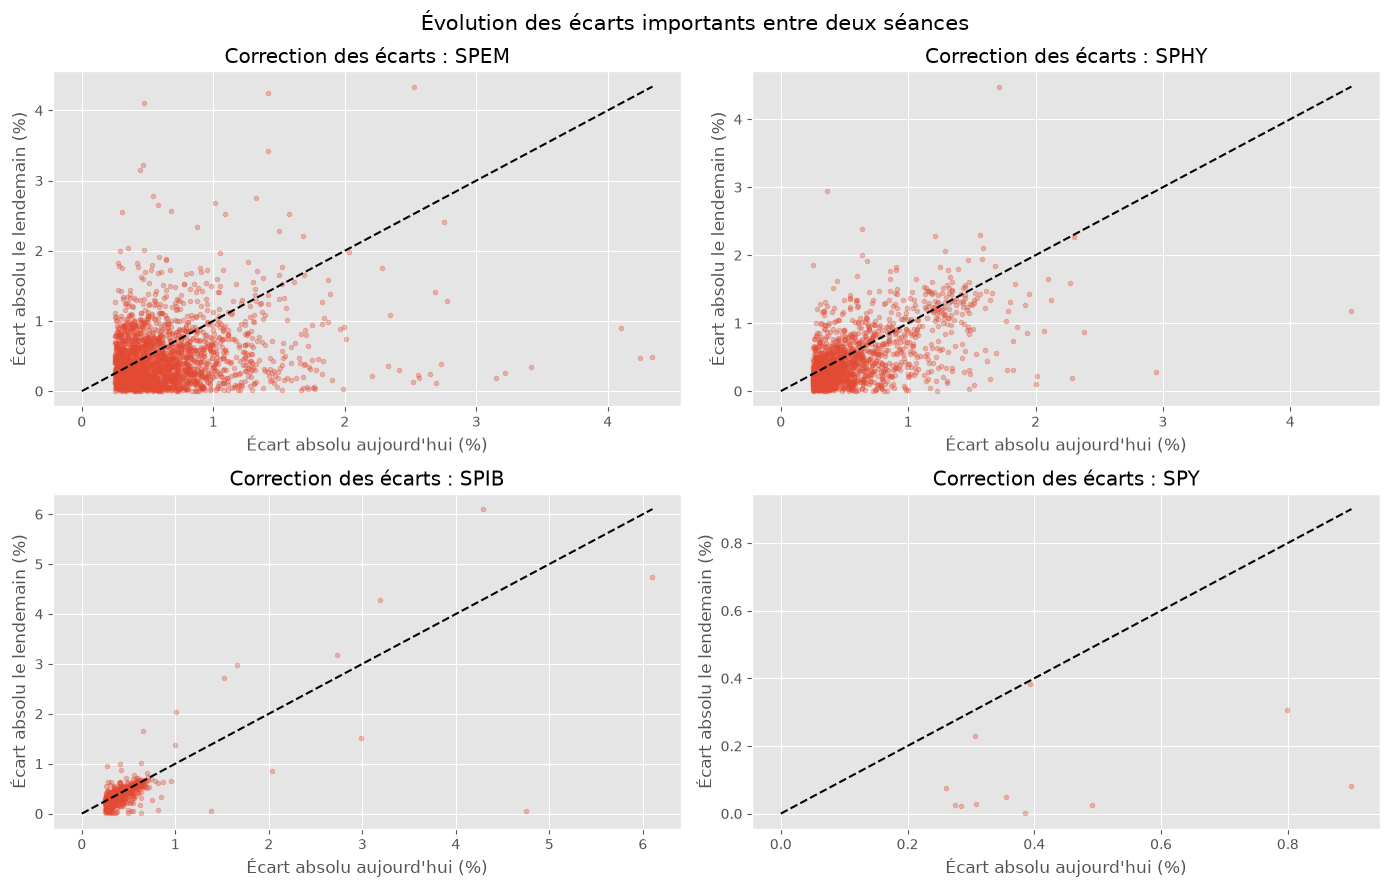

In [6]:
donnees_ecarts_importants, vitesse_correction = compute_next_day_correction(
    donnees, seuil_ecart=0.25
)
display(vitesse_correction.round(4))

_ = plot_next_day_correction(donnees_ecarts_importants)

### Résultats de l'étude des corrections

Le taux de correction des écarts importants est de **68,67 % pour SPEM** (variation moyenne : −0,1663 point de pourcentage), **67,28 % pour SPHY** (−0,1050), **65,22 % pour SPIB** (−0,0526) et **100 % pour SPY** (−0,3203).

On observe donc que dans la majorité des cas les arbitrages mènent les écarts à se résorber.

Le résultat de SPY doit être interprété avec prudence car il ne repose que sur **11 dates**. Dans l'ensemble, les écarts importants ont tendance à diminuer dès la séance suivante, sans disparaître systématiquement.

# Conclusion et limites

## Conclusion

L'ETF et le portefeuille sous-jacent peuvent représenter la même exposition tout en ayant des prix différents, car le prix de l'ETF est déterminé en continu par l'offre et la demande alors que la NAV est calculée à partir de la valorisation des actifs du portefeuille, souvent à un autre moment et avec d'autres conventions. Les résultats montrent que les écarts sont faibles pour SPY, plus importants pour SPEM et SPHY, qu'ils s'amplifient généralement lorsque la volatilité est forte et qu'ils se corrigent souvent dès le lendemain.

## Limites du projet

- La NAV et le prix de clôture peuvent correspondre à des moments différents de la même journée.
- Le VIX est un indicateur de volatilité du S&P 500, pas une mesure spécifique de chacun des ETF.
- Les seuils `0,25 %`, `0,5 %`, `1 %`, `VIX < 15` et `VIX ≥ 30` sont des choix d'analyse ; ils ne constituent pas des seuils universels.
- Le volume est un proxy imparfait de la liquidité.
- Le projet ne rend pas compte de causalité mais de tendances.